# Q3 · Steps 5–6 — Compare AutoML with the baseline and save the best model

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from lab_utils import save_json, load_json, savefig
import q3_common as q3
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import platform, sklearn, datetime

df = q3.load_adult(ROOT / "data" / "q3_adult")
X_train, X_test, y_train, y_test = q3.split_data(df)
base = joblib.load(ROOT / "models" / "baseline_model.joblib")
auto = joblib.load(ROOT / "models" / "automl_model.joblib")
B = load_json(ROOT / "results" / "q3" / "baseline_results.json"); A = load_json(ROOT / "results" / "q3" / "automl_results.json")

## 1. Side-by-side comparison on the same test set

In [4]:
def model_row(name, pipe, train_time, path):
    return {"model": name, **q3.compute_metrics(pipe, X_test, y_test), "train/search time (s)": train_time,
            "inference (ms/row)": q3.time_inference(pipe, X_test), "file size (MB)": path.stat().st_size / 1e6,
            "complexity": q3.describe_complexity(pipe)["final_estimator"] + " | " + q3.describe_complexity(pipe)["size"]}
base_time = next(r["train_time_s"] for r in B["table"] if r["model"] == B["main_baseline"])
cmp = pd.DataFrame([model_row("Baseline: Logistic Regression", base, base_time, ROOT / "models" / "baseline_model.joblib"),
                    model_row("AutoML: TPOT", auto, A["search_time_s"], ROOT / "models" / "automl_model.joblib")])
display(cmp.round(4))

,model,accuracy,precision,recall,f1,roc_auc,train/search time (s),inference (ms/row),file size (MB),complexity
0,Baseline: Logistic Regression,0.8569,0.7439,0.6186,0.6755,0.9088,1.7491,0.0113,0.0093,LogisticRegression | 106 coefficients
1,AutoML: TPOT,0.7476,0.4863,0.8603,0.6214,0.8789,2012.3846,0.0656,0.1004,MinMaxScaler -> SelectFwe -> FeatureUnion -> F...


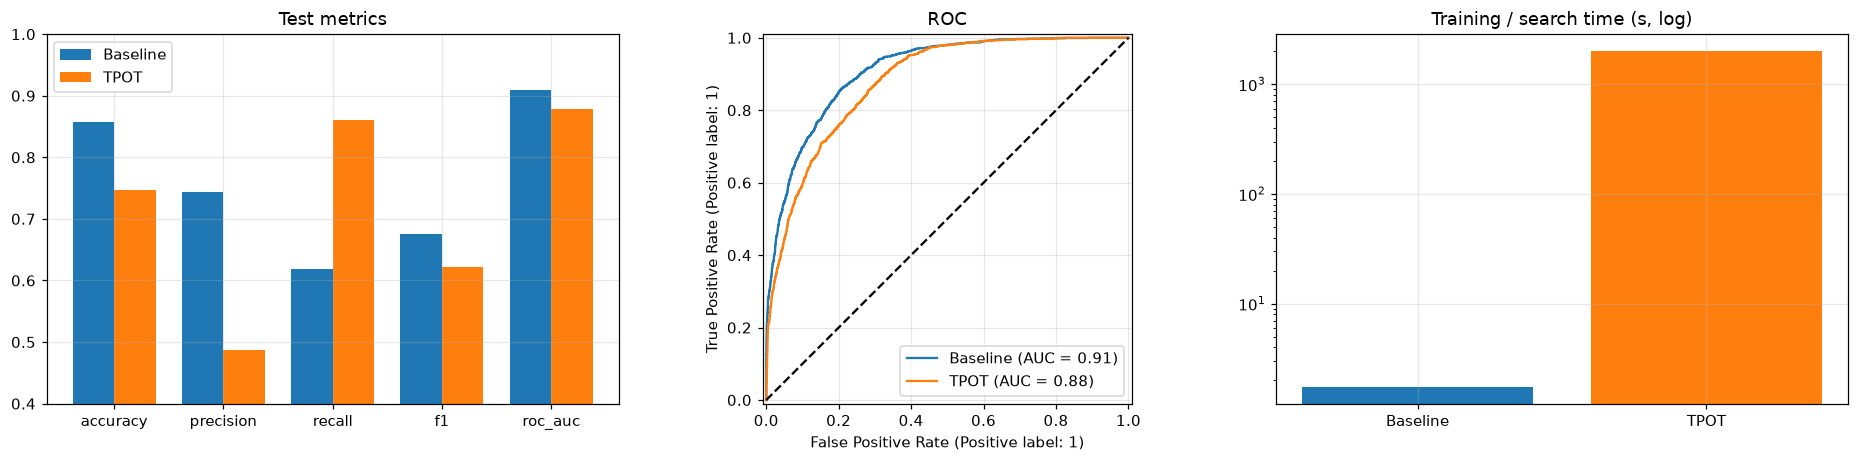

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
mets = ["accuracy", "precision", "recall", "f1", "roc_auc"]; x = np.arange(len(mets)); w = 0.38
axes[0].bar(x - w/2, cmp.loc[0, mets], w, label="Baseline"); axes[0].bar(x + w/2, cmp.loc[1, mets], w, label="TPOT")
axes[0].set_xticks(x); axes[0].set_xticklabels(mets); axes[0].set_ylim(0.4, 1); axes[0].legend(); axes[0].set_title("Test metrics")
for n, p in [("Baseline", base), ("TPOT", auto)]: RocCurveDisplay.from_estimator(p, X_test, y_test, ax=axes[1], name=n)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC")
axes[2].bar(["Baseline", "TPOT"], cmp["train/search time (s)"], color=["tab:blue", "tab:orange"]); axes[2].set_yscale("log"); axes[2].set_title("Training / search time (s, log)")
plt.tight_layout(); savefig(fig, "q3", "model_comparison"); plt.show()

## 2. Choose the best model
Selection metric: **ROC-AUC on the test set** (ties broken by F1). *Limitation:* choosing on the test set slightly favours it; with more time one would pick on a separate validation set.

In [6]:
best_idx = int(cmp.sort_values(["roc_auc", "f1"], ascending=False).index[0])
best_name = cmp.loc[best_idx, "model"]; best_pipe = [base, auto][best_idx]
print("Best model:", best_name)

Best model: Baseline: Logistic Regression


## 3. Feature importance (model-agnostic permutation importance on the raw input features)
Each raw feature is shuffled in turn; the drop in ROC-AUC measures how much the model relies on it. Works for *any* pipeline, including the TPOT one.

,feature,importance,std
6,marital_status,0.0960,0.0036
2,capital_gain,0.0378,0.0011
0,age,0.0326,0.0028
1,education_num,0.0299,0.0018
7,occupation,0.0155,0.0010
8,relationship,0.0091,0.0005
4,hours_per_week,0.0090,0.0007
10,sex,0.0073,0.0010
3,capital_loss,0.0037,0.0004
5,workclass,0.0014,0.0004


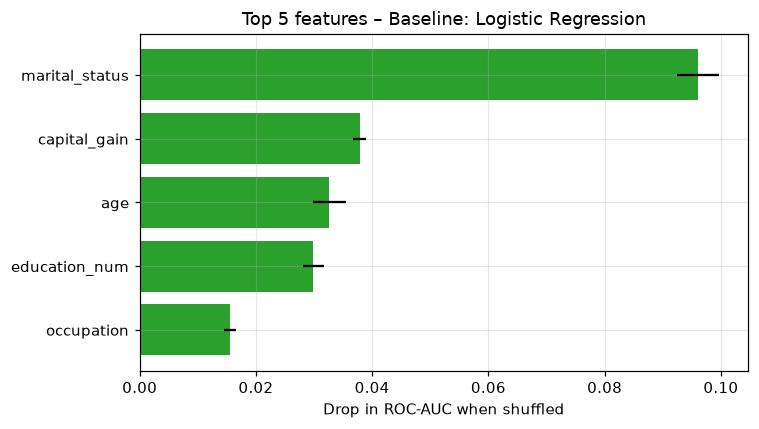

In [7]:
sample = X_test.sample(min(6000, len(X_test)), random_state=0); ys = y_test.loc[sample.index]
pi = permutation_importance(best_pipe, sample, ys, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=1)
imp = pd.DataFrame({"feature": sample.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
display(imp.head(10).round(4))
fig, ax = plt.subplots(figsize=(7, 4)); top = imp.head(5)[::-1]
ax.barh(top.feature, top.importance, xerr=top["std"], color="tab:green"); ax.set_xlabel("Drop in ROC-AUC when shuffled"); ax.set_title(f"Top 5 features – {best_name}")
plt.tight_layout(); savefig(fig, "q3", "feature_importance"); plt.show()

## 4. Save the best model + metadata for the API

In [8]:
joblib.dump(best_pipe, ROOT / "models" / "best_model.joblib")
test_metrics = q3.compute_metrics(best_pipe, X_test, y_test)
meta = {"model_name": best_name, "test_metrics": test_metrics, "importance_method": "permutation importance (drop in ROC-AUC)",
        "feature_importance": [{"feature": r.feature, "importance": round(float(r.importance), 5)} for r in imp.itertuples()],
        "schema": q3.build_schema(X_train), "input_columns": q3.INPUT_COLUMNS,
        "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
        "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__}}
save_json(meta, ROOT / "models" / "model_metadata.json")
save_json({"comparison": cmp.to_dict("records"), "best_model": best_name, "top5": meta["feature_importance"][:5]},
          ROOT / "results" / "q3" / "comparison_results.json")
print("Saved models/best_model.joblib, models/model_metadata.json ✔")

Saved models/best_model.joblib, models/model_metadata.json ✔


## 5. Advantages and limitations (use these ideas in your discussion)
| | Baseline (Logistic Regression) | AutoML (TPOT) |
|---|---|---|
| **Pros** | fast to train, easy to explain (coefficients), tiny model, low latency | searches many models/hyper-parameters automatically, often a little better, less manual tuning |
| **Cons** | only linear decision boundary, needs manual feature engineering | long search time, non-deterministic, may return a complex hard-to-explain pipeline, gain over a good baseline can be small |